# Netflix Data Analysis

Cleaning and exploring 8,800+ Netflix movies and TV shows to answer four questions:

1. Does Netflix have more movies or TV shows?
2. How many titles did Netflix add each year?
3. Which countries make the most Netflix content?
4. How long is a typical Netflix movie?

**Data:** [Netflix Movies and TV Shows](https://www.kaggle.com/shivamb/netflix-shows) on Kaggle. Download it and put `archive.zip` in the same folder as this notebook.

## Part 1: Load and look

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data (pandas can read the CSV straight from the zip file)
df = pd.read_csv("archive.zip")

print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
print("Missing values per column:")
display(df.isna().sum())

Missing values per column:


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

## Part 2: Clean the data

Problems found while exploring:
- `director`, `cast` and `country` have many missing values
- a few rows are missing `date_added`, `rating` or `duration` (including 3 rows where the duration was typed into the rating column)
- `date_added` is text, not a date
- `duration` mixes minutes ("90 min") and seasons ("2 Seasons")

In [3]:
# Fix 1: fill missing text with "Unknown"
df["director"] = df["director"].fillna("Unknown")
df["cast"]     = df["cast"].fillna("Unknown")
df["country"]  = df["country"].fillna("Unknown")

print("Missing directors now:", df["director"].isna().sum())

Missing directors now: 0


In [4]:
# Fix 2: remove the few broken rows
print("Rows before:", len(df))
df = df.dropna(subset=["date_added", "rating", "duration"])
print("Rows after:", len(df))

Rows before: 8807
Rows after: 8790


In [5]:
# Fix 3: get the year from the date text ("September 25, 2021" -> 2021)
df["year_added"] = df["date_added"].str.strip().str[-4:]
df["year_added"] = pd.to_numeric(df["year_added"])

display(df[["date_added", "year_added"]].head())

,date_added,year_added
0,"September 25, 2021",2021
1,"September 24, 2021",2021
2,"September 24, 2021",2021
3,"September 24, 2021",2021
4,"September 24, 2021",2021


In [6]:
# Fix 4: get the number from duration ("90 min" -> 90, "2 Seasons" -> 2)
df["duration_num"] = df["duration"].str.split(" ").str[0]
df["duration_num"] = pd.to_numeric(df["duration_num"])

display(df[["type", "duration", "duration_num"]].head())

,type,duration,duration_num
0,Movie,90 min,90
1,TV Show,2 Seasons,2
2,TV Show,1 Season,1
3,TV Show,1 Season,1
4,TV Show,2 Seasons,2


In [7]:
# Final check: every column should show 0 missing
display(df.isna().sum())
print("Clean data:", df.shape)

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
year_added      0
duration_num    0
dtype: int64

Clean data: (8790, 14)


## Part 3: Answer the questions

### Question 1: More movies or TV shows?

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

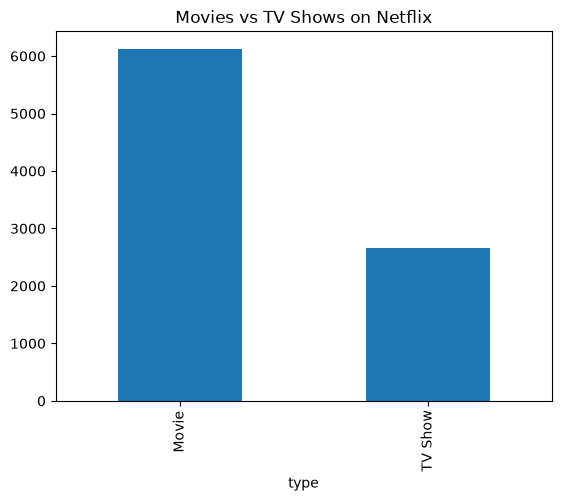

In [8]:
counts = df["type"].value_counts()
display(counts)

counts.plot(kind="bar", title="Movies vs TV Shows on Netflix")
plt.show()

### Question 2: How many titles did Netflix add each year?

year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1648
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64

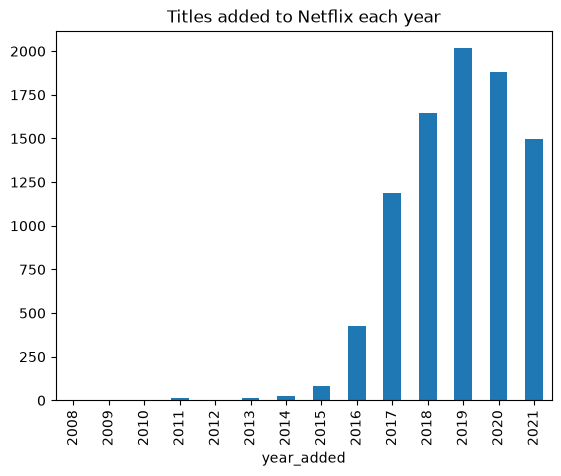

In [9]:
per_year = df["year_added"].value_counts().sort_index()
display(per_year)

per_year.plot(kind="bar", title="Titles added to Netflix each year")
plt.show()

### Question 3: Which countries make the most content?

country
United States     2809
India              972
United Kingdom     418
Japan              243
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
Name: count, dtype: int64

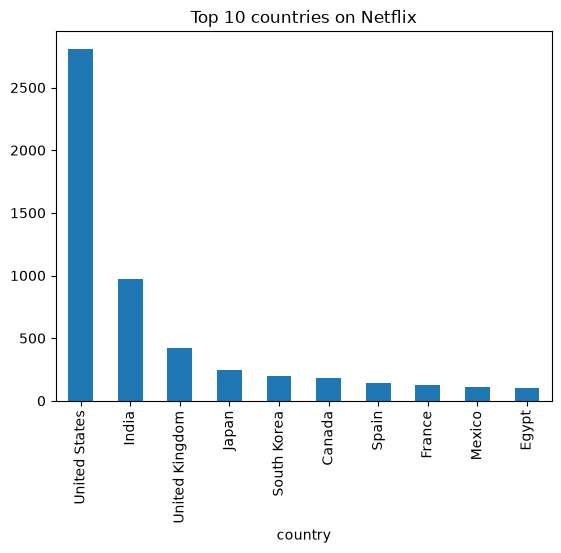

In [10]:
known = df[df["country"] != "Unknown"]
top10 = known["country"].value_counts().head(10)
display(top10)

top10.plot(kind="bar", title="Top 10 countries on Netflix")
plt.show()

### Question 4: How long is a typical movie?

Average movie length: 100 minutes
Median movie length: 98.0 minutes


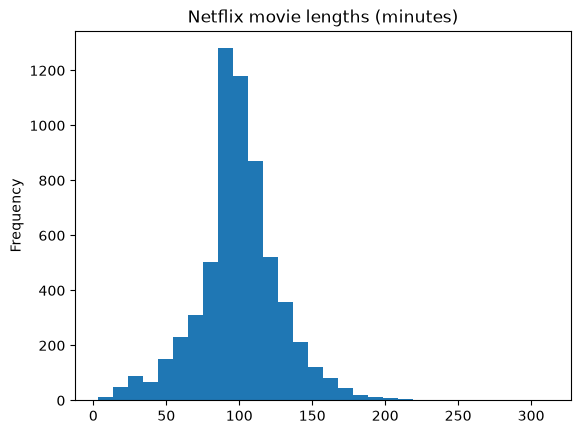

In [11]:
movies = df[df["type"] == "Movie"]

print("Average movie length:", round(movies["duration_num"].mean()), "minutes")
print("Median movie length:", movies["duration_num"].median(), "minutes")

movies["duration_num"].plot(kind="hist", bins=30, title="Netflix movie lengths (minutes)")
plt.show()

## Findings

*(Check these against the outputs above and update the numbers if needed.)*

1. **Movies or TV shows?** Netflix has about 6,100 movies and 2,700 TV shows, so roughly 70% of the catalogue is movies.
2. **Titles added per year:** additions peaked in 2019. The data stops in September 2021, so 2021 is incomplete.
3. **Top countries:** the United States produces the most content, followed by India and the United Kingdom.
4. **Movie length:** a typical movie is about 100 minutes long; most are between 80 and 120 minutes.

**Limitation:** some titles list several countries (e.g. "United States, Canada"); these are counted as their own group here.

In [12]:
import os
print(os.getcwd())

C:\Users\Hassan Yerima\Kaggle
